# Clusters da Bacia do Uruguai — Visão Geral

Este notebook apresenta:

1. **Mapa dos clusters** — as 9 sub-bacias do Rio Uruguai (SNIRH) com cores distintas
2. **Pontos de grade Xavier** dentro de cada cluster
3. **Série temporal do acumulado mensal** de precipitação por cluster
4. **Série temporal da anomalia mensal** por cluster (acumulado − climatologia mensal)

---

**Fonte dos dados**
- Shapefile: `data/clusters/bacias/SNIRH_SUbBaciasDNAEE.shp` → sub-bacias com `DNS_DNB_CD = 7`
- Precipitação: Xavier mensal 0.1° (`pr_monthly_1961_2019_BRAZIL_combined.nc`), 708 meses

In [5]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import netCDF4 as nc4
import shapefile
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath
from pathlib import Path

plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'

# Caminhos
SHP_PATH   = '../data/clusters/uruguai/URUGUAI_recortado.shp'
SHP_BRASIL = '../data/clusters/bacias/SNIRH_RegioesHidrograficas.shp'
XAVIER_NC  = '../data/processed/xavier_monthly/pr_monthly_1961_2019_BRAZIL_combined.nc'
MASKS_NPZ  = '../data/processed/uruguai_cluster_masks.npz'

# Bbox do recorte
LAT_MIN, LAT_MAX = -32.3, -25.7
LON_MIN, LON_MAX = -58.1, -48.8

R_EARTH = 6_371_000.0  # metros

# Paleta de cores para os clusters
CLUSTER_CMAP = plt.colormaps.get_cmap('tab10')

print('Imports OK')

Imports OK


---
## 1. Carregar clusters e gradeXavier

In [6]:
# ── 1a. Clusters do Uruguai (novo shapefile) ──────────────────────────────────
sf = shapefile.Reader(SHP_PATH, encoding='utf-8')
clusters = list(zip(sf.records(), sf.shapes()))
cluster_names = [rec['nome'] for rec, _ in clusters]
n_clusters = len(clusters)

print(f'{n_clusters} clusters encontrados:')
for rec, shp in clusters:
    print(f"  id={rec['id']}  {rec['nome']}  bbox={[round(v,2) for v in shp.bbox]}")

# ── 1b. Grade Xavier (lat/lon do recorte) ─────────────────────────────────────
with nc4.Dataset(XAVIER_NC) as nc:
    lats_all = np.array(nc.variables['latitude'][:])
    lons_all = np.array(nc.variables['longitude'][:])
    times_raw = np.array(nc.variables['time'][:])
    time_units = nc.variables['time'].units
    time_cal   = getattr(nc.variables['time'], 'calendar', 'standard')

lat_mask = (lats_all >= LAT_MIN) & (lats_all <= LAT_MAX)
lon_mask = (lons_all >= LON_MIN) & (lons_all <= LON_MAX)
lats = lats_all[lat_mask]
lons = lons_all[lon_mask]
lons2d, lats2d = np.meshgrid(lons, lats)
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])

# Série temporal
try:
    import cftime
    dates = cftime.num2date(times_raw, time_units, time_cal)
    time_idx = pd.DatetimeIndex([pd.Timestamp(d.year, d.month, d.day) for d in dates])
except Exception:
    from netCDF4 import num2date
    dates = num2date(times_raw, time_units)
    time_idx = pd.DatetimeIndex([pd.Timestamp(str(d)[:10]) for d in dates])

time_months = time_idx.month.values
n_time = len(time_idx)
print(f'\nGrade Xavier recortada: {len(lats)} lats × {len(lons)} lons = {len(grid_pts)} pontos')
print(f'Série temporal: {time_idx[0].date()} → {time_idx[-1].date()}  ({n_time} meses)')

4 clusters encontrados:
  id=1  CLUSTER1_URUGUAI  bbox=[-57.64, -31.83, -53.77, -28.69]
  id=2  CLUSTER2_URUGUAI  bbox=[-56.13, -29.69, -52.9, -27.25]
  id=4  CLUSTER4_URUGUAI  bbox=[-51.6, -28.77, -49.28, -26.58]
  id=3  CLUSTER3_URUGUAI  bbox=[-54.11, -28.33, -51.19, -26.24]

Grade Xavier recortada: 66 lats × 93 lons = 6138 pontos
Série temporal: 1961-01-31 → 2019-12-31  (708 meses)


In [7]:
# ── 1c. Máscaras ponto-no-polígono ────────────────────────────────────────────
# Tenta carregar o .npz pré-computado; se não existir, calcula agora.
npz_path = Path(MASKS_NPZ)
if npz_path.exists():
    npz = np.load(str(npz_path), allow_pickle=True)
    masks_flat = npz['masks_flat'].astype(bool)  # (n_clusters, n_pts)
    print('Máscaras carregadas do .npz pré-computado.')
else:
    print('Calculando máscaras (point-in-polygon)...')
    masks_flat = []
    for rec, shp in clusters:
        mask = np.zeros(len(grid_pts), dtype=bool)
        parts = list(shp.parts) + [len(shp.points)]
        for i in range(len(shp.parts)):
            pts = np.array(shp.points[parts[i]:parts[i+1]])
            if len(pts) >= 3:
                mask |= MplPath(pts).contains_points(grid_pts)
        masks_flat.append(mask)
        print(f"  {rec['DNS_NM']}: {mask.sum()} pontos")
    masks_flat = np.array(masks_flat, dtype=bool)

for i, (rec, _) in enumerate(clusters):
    print(f"  {cluster_names[i]:<45}  {masks_flat[i].sum():4d} pontos")

Máscaras carregadas do .npz pré-computado.
  CLUSTER1_URUGUAI                                514 pontos
  CLUSTER2_URUGUAI                                395 pontos
  CLUSTER4_URUGUAI                                275 pontos
  CLUSTER3_URUGUAI                                420 pontos


---
## 2. Mapa dos Clusters

ShapefileException: Unable to open ../data/clusters/bacias/SNIRH_RegioesHidrograficas.dbf or ../data/clusters/bacias/SNIRH_RegioesHidrograficas.shp.

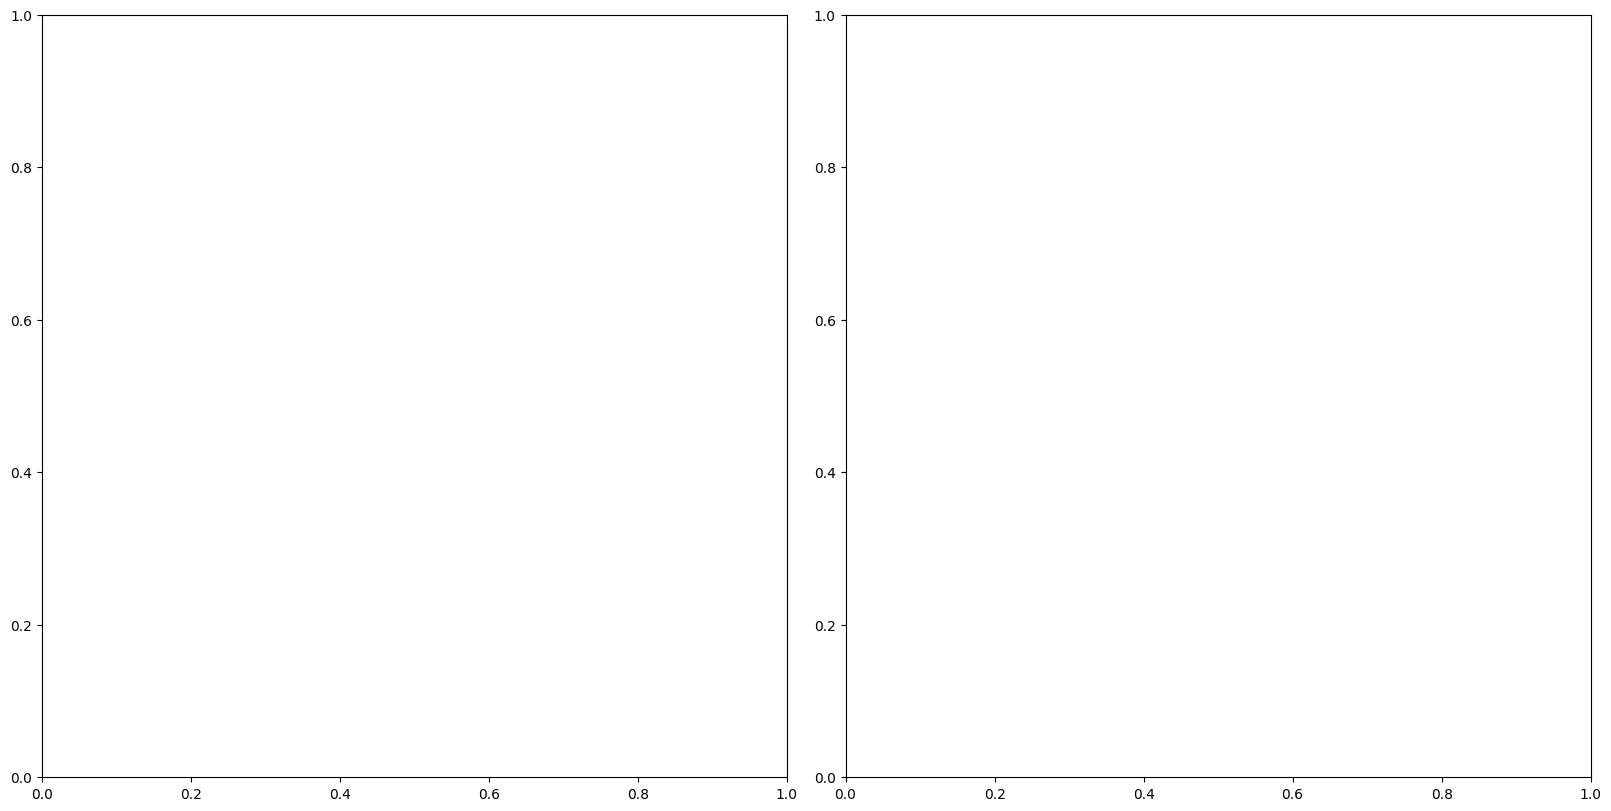

In [8]:
def get_patches(shp, **kwargs):
    """Converte um shape em lista de patches matplotlib."""
    patches = []
    parts = list(shp.parts) + [len(shp.points)]
    for i in range(len(shp.parts)):
        pts = np.array(shp.points[parts[i]:parts[i+1]])
        patches.append(MplPolygon(pts, closed=True, **kwargs))
    return patches


fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

# ── Painel esquerdo: mapa com polígonos dos clusters ─────────────────────────
ax = axes[0]

# Contexto: bacia do Uruguai inteira (SNIRH regiões)
sf_br = shapefile.Reader(SHP_BRASIL, encoding='utf-8')
for rec_br, shp_br in zip(sf_br.records(), sf_br.shapes()):
    color = '#e0e0e0' if rec_br['RHI_NM'] != 'URUGUAI' else '#b0c4de'
    for p in get_patches(shp_br):
        p.set_facecolor(color)
        p.set_edgecolor('#aaaaaa')
        p.set_linewidth(0.5)
        ax.add_patch(p)

# Sub-bacias do Uruguai com cores distintas
legend_handles = []
for i, (rec, shp) in enumerate(clusters):
    color = CLUSTER_CMAP(i)
    for p in get_patches(shp):
        p.set_facecolor(color)
        p.set_edgecolor('white')
        p.set_linewidth(0.8)
        p.set_zorder(2)
        ax.add_patch(p)
    # Centroide para número
    pts_all = np.array(shp.points)
    cx, cy = pts_all[:, 0].mean(), pts_all[:, 1].mean()
    ax.text(cx, cy, str(i+1), ha='center', va='center', fontsize=8,
            fontweight='bold', color='white', zorder=3)
    legend_handles.append(
        mpatches.Patch(facecolor=color, edgecolor='white',
                       label=f"{i+1}. {rec['DNS_NM'][:35]} ({masks_flat[i].sum()} pts)")
    )

# Pontos de grade Xavier (todos, em cinza claro)
ax.scatter(lons2d.ravel(), lats2d.ravel(), s=0.8, color='#888888',
           alpha=0.25, zorder=1, label='Grade Xavier 0.1°')

ax.set_xlim(LON_MIN - 0.5, LON_MAX + 0.5)
ax.set_ylim(LAT_MIN - 0.5, LAT_MAX + 0.5)
ax.set_xlabel('Longitude (°)', fontsize=10)
ax.set_ylabel('Latitude (°)', fontsize=10)
ax.set_title('Sub-bacias do Rio Uruguai\n(SNIRH — DNS_DNB_CD = 7)',
             fontsize=12, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3, linewidth=0.4)
ax.legend(handles=legend_handles, loc='upper right', fontsize=6.5,
          framealpha=0.92, edgecolor='gray', title='Clusters', title_fontsize=8)

# ── Painel direito: pontos de grade coloridos por cluster ────────────────────
ax2 = axes[1]

# Fundo: contexto da bacia do Uruguai
sf_br2 = shapefile.Reader(SHP_BRASIL, encoding='utf-8')
for rec_br, shp_br in zip(sf_br2.records(), sf_br2.shapes()):
    color = '#e0e0e0' if rec_br['RHI_NM'] != 'URUGUAI' else '#d4e3f0'
    for p in get_patches(shp_br):
        p.set_facecolor(color)
        p.set_edgecolor('#aaaaaa')
        p.set_linewidth(0.5)
        ax2.add_patch(p)

# Pontos de grade coloridos pelo cluster
point_colors = np.full(len(grid_pts), -1, dtype=int)
for i in range(n_clusters):
    point_colors[masks_flat[i]] = i

# Pontos sem cluster em cinza
no_cluster = point_colors == -1
ax2.scatter(grid_pts[no_cluster, 0], grid_pts[no_cluster, 1],
            s=4, color='#cccccc', alpha=0.5, zorder=1)

# Pontos com cluster coloridos
for i in range(n_clusters):
    in_cluster = point_colors == i
    ax2.scatter(grid_pts[in_cluster, 0], grid_pts[in_cluster, 1],
                s=8, color=CLUSTER_CMAP(i), alpha=0.85, zorder=2,
                label=f'{i+1}. {cluster_names[i][:25]}')

ax2.set_xlim(LON_MIN - 0.5, LON_MAX + 0.5)
ax2.set_ylim(LAT_MIN - 0.5, LAT_MAX + 0.5)
ax2.set_xlabel('Longitude (°)', fontsize=10)
ax2.set_ylabel('Latitude (°)', fontsize=10)
ax2.set_title('Pontos de Grade Xavier por Cluster\n(0.1° de resolução)',
              fontsize=12, fontweight='bold')
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3, linewidth=0.4)

fig.suptitle('Bacia do Uruguai — Clusters e Grade de Precipitação',
             fontsize=14, fontweight='bold')

out_dir = Path('../results')
out_dir.mkdir(exist_ok=True)
fig.savefig(out_dir / 'uruguai_clusters_mapa.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em results/uruguai_clusters_mapa.png')

---
## 3. Calcular Acumulado Mensal e Anomalia por Cluster

In [ ]:
# Carregar precipitação do recorte (708 × n_lat × n_lon)
print('Carregando precipitação Xavier (recorte do Uruguai)...')
with nc4.Dataset(XAVIER_NC) as nc:
    lat_idx = np.where(lat_mask)[0]
    lon_idx = np.where(lon_mask)[0]
    pr_crop = np.array(
        nc.variables['pr'][
            :,
            lat_idx[0]:lat_idx[-1]+1,
            lon_idx[0]:lon_idx[-1]+1
        ]
    )  # (n_time, n_lat, n_lon)

n_lat, n_lon = len(lats), len(lons)
print(f'  Shape: {pr_crop.shape}')

# Pesos de integração trapezoidal esférica: cos(lat)
cos_lat = np.cos(np.deg2rad(lats))           # (n_lat,)
lat_rad = np.deg2rad(lats)                   # para trapezoid
lon_rad = np.deg2rad(lons)

# Para cada cluster: integração espacial → climatologia → anomalia
from scipy.integrate import trapezoid

cluster_data = {}
for i, name in enumerate(cluster_names):
    mask = masks_flat[i].reshape(n_lat, n_lon)  # (n_lat, n_lon)

    # Aplicar máscara (NaN fora do cluster) e peso cos(lat)
    pr_masked = pr_crop.copy()                   # (n_time, n_lat, n_lon)
    pr_masked[:, ~mask] = 0.0                    # zero fora (trapezoid não aceita NaN)
    pr_weighted = pr_masked * cos_lat[np.newaxis, :, np.newaxis]

    # Integração trapezoidal: lat → (n_time, n_lon), lon → (n_time,)
    int_lat = trapezoid(pr_weighted, lat_rad, axis=1)   # (n_time, n_lon)
    pr_c    = trapezoid(int_lat,     lon_rad, axis=1)   # (n_time,)
    pr_c   *= R_EARTH**2                                # m³/mês equivalente

    clim = np.array([pr_c[time_months == m].mean() for m in range(1, 13)])
    anom = pr_c - clim[time_months - 1]

    cluster_data[name] = {'accum': pr_c, 'clim': clim, 'anom': anom,
                          'n_pts': mask.sum()}
    print(f'  {name:<30}  n_pts={mask.sum():4d}  '
          f'anom μ={anom.mean():+.3e}  σ={anom.std():.3e}')

---
## 4. Série Temporal do Acumulado Mensal

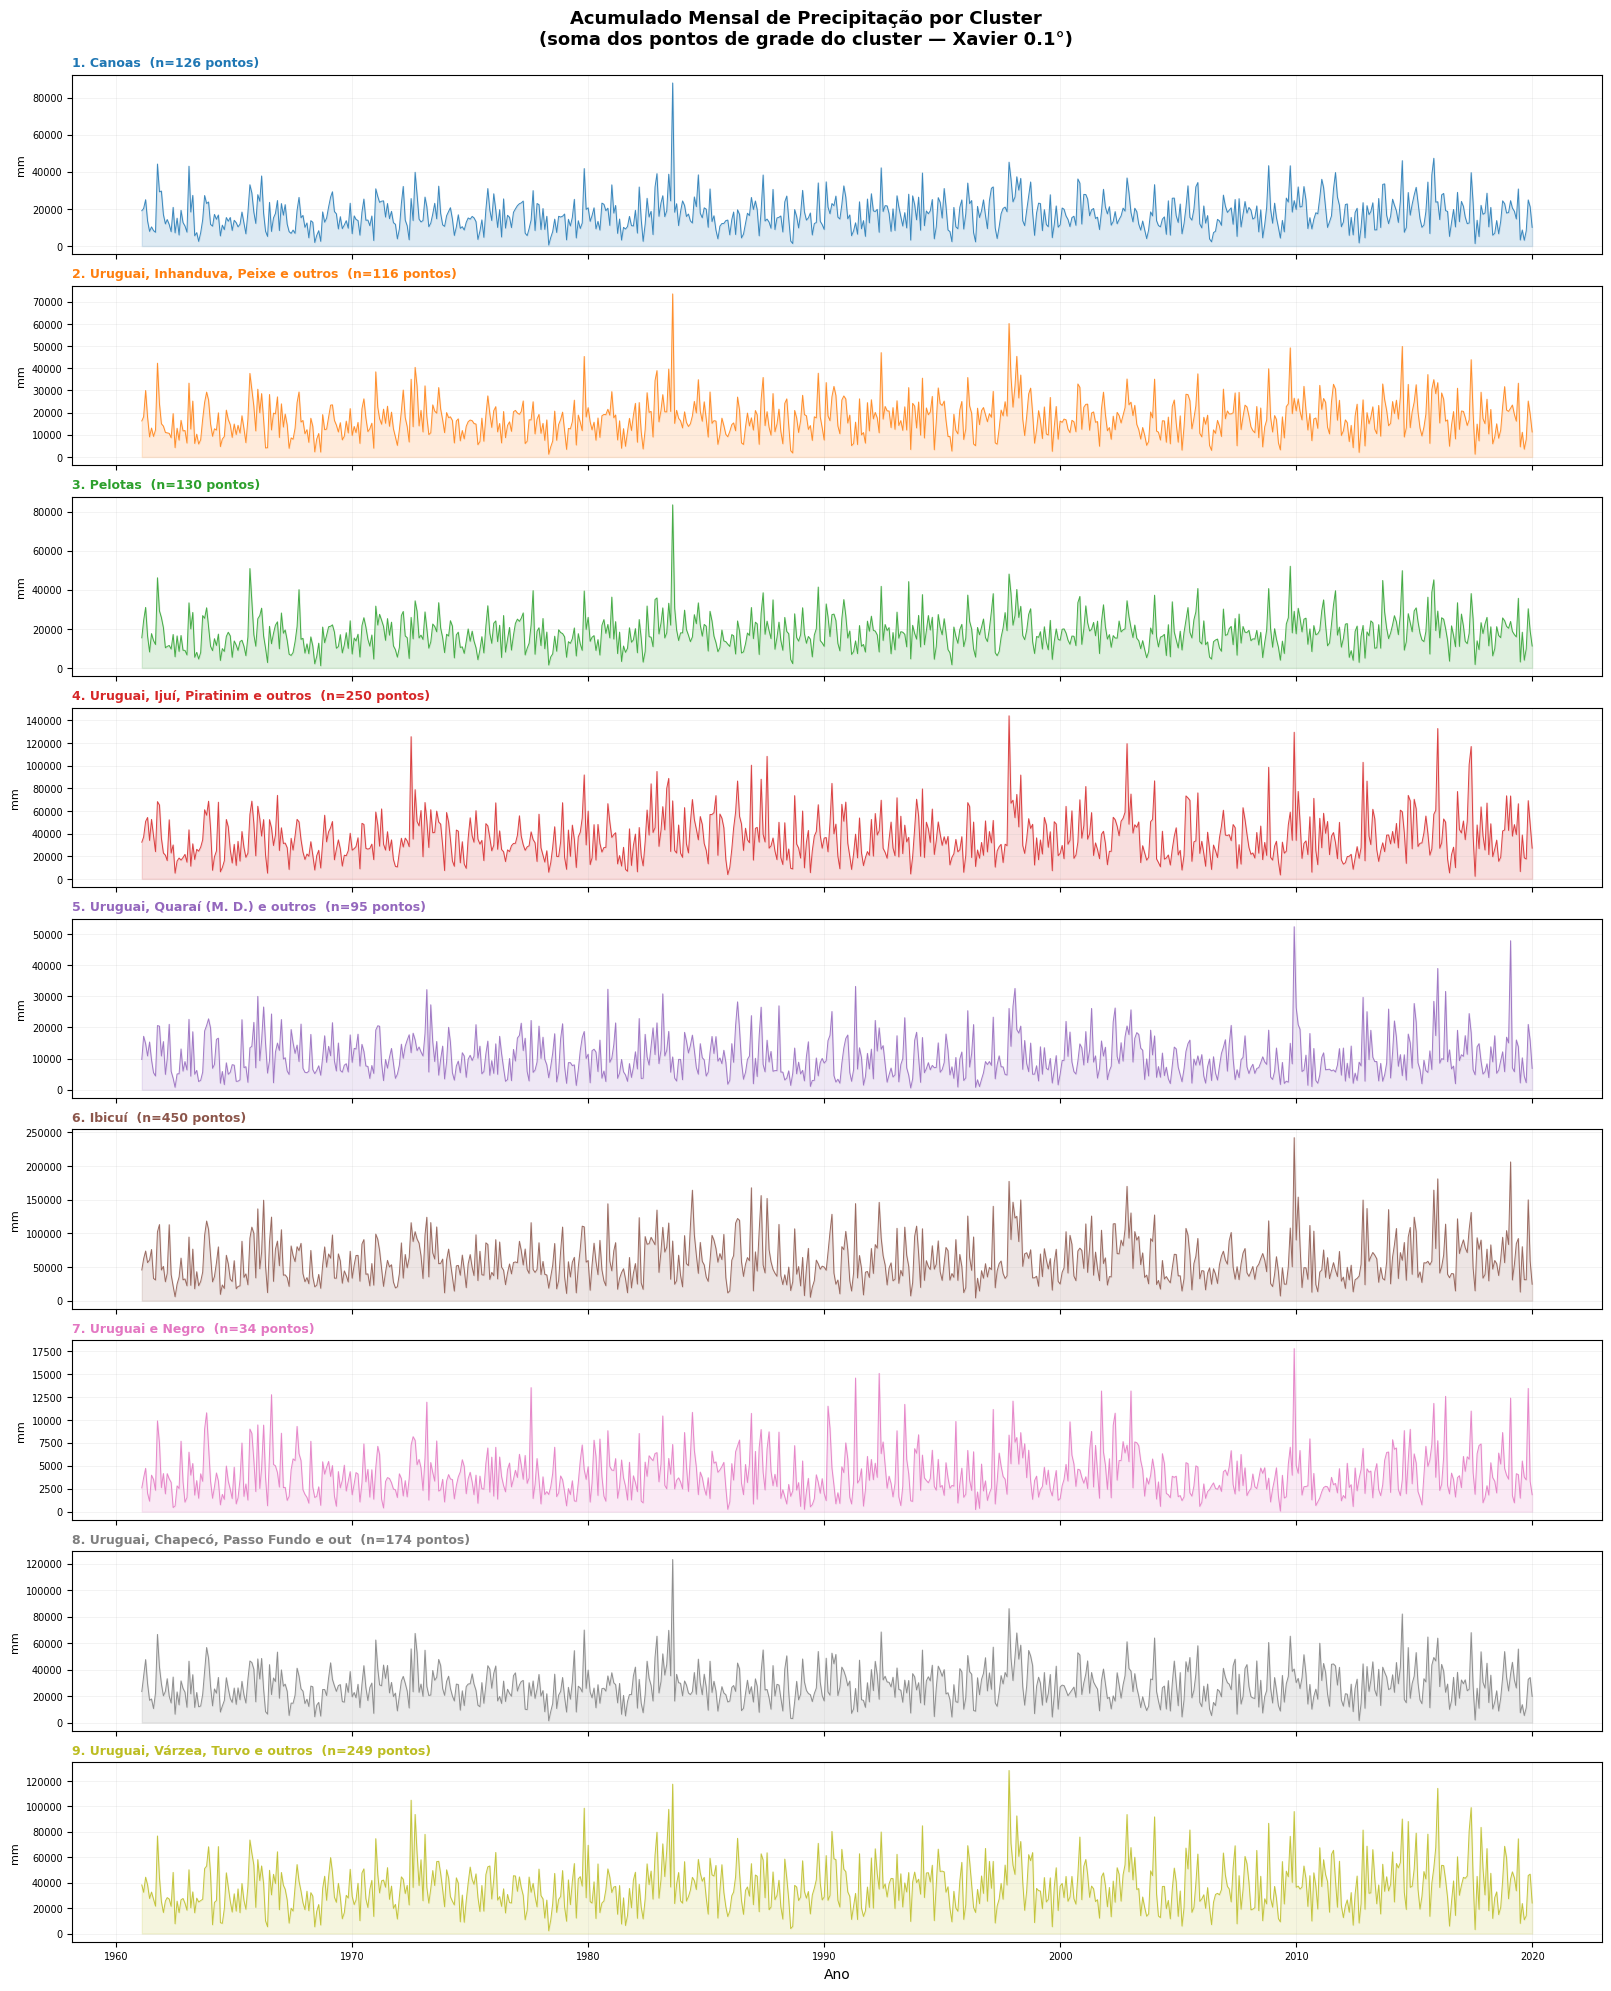

Figura salva em results/uruguai_clusters_acumulado.png


In [ ]:
fig, axes = plt.subplots(n_clusters, 1,
                         figsize=(16, 2.2 * n_clusters),
                         sharex=True, constrained_layout=True)

for i, (name, d) in enumerate(cluster_data.items()):
    ax = axes[i]
    color = CLUSTER_CMAP(i)
    ax.plot(time_idx, d['accum'], linewidth=0.7, color=color, alpha=0.85)
    ax.fill_between(time_idx, d['accum'], alpha=0.15, color=color)
    ax.set_ylabel('mm', fontsize=8)
    short = name[:35]
    ax.set_title(f'{i+1}. {short}  (n={d["n_pts"]} pontos)', fontsize=9,
                 color=color, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.25, linewidth=0.4)
    ax.tick_params(labelsize=7)

axes[-1].set_xlabel('Ano', fontsize=10)
fig.suptitle('Acumulado Mensal de Precipitação por Cluster\n'
             '(soma dos pontos de grade do cluster — Xavier 0.1°)',
             fontsize=13, fontweight='bold')

fig.savefig(Path('../results') / 'uruguai_clusters_acumulado.png',
            dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em results/uruguai_clusters_acumulado.png')

---
## 5. Climatologia Mensal por Cluster

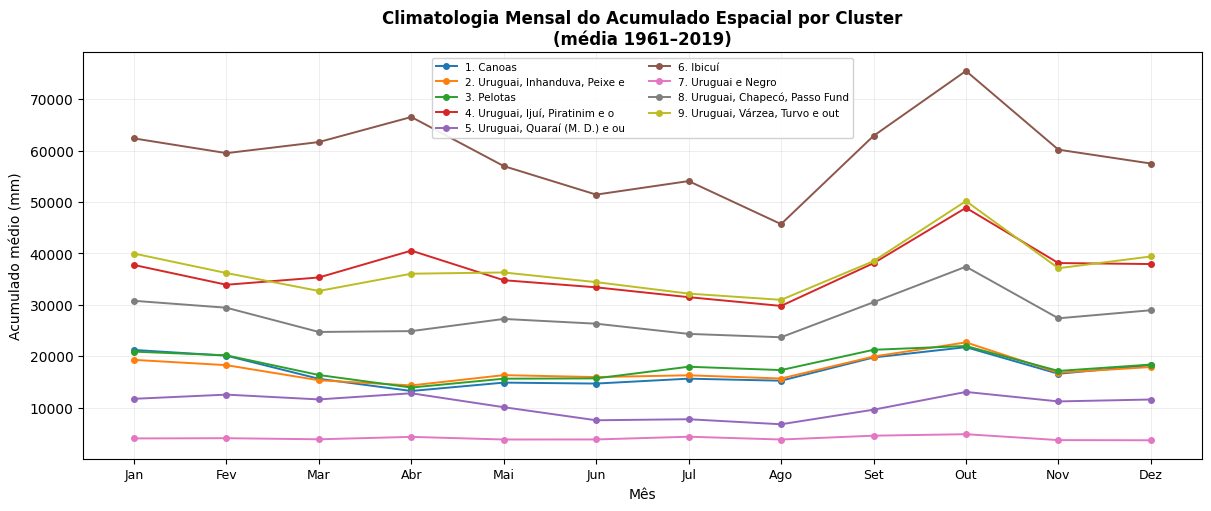

In [ ]:
MONTH_LABELS = ['Jan','Fev','Mar','Abr','Mai','Jun',
                'Jul','Ago','Set','Out','Nov','Dez']

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)

for i, (name, d) in enumerate(cluster_data.items()):
    ax.plot(range(1, 13), d['clim'], marker='o', markersize=4,
            linewidth=1.4, color=CLUSTER_CMAP(i),
            label=f"{i+1}. {name[:28]}")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_LABELS, fontsize=9)
ax.set_xlabel('Mês', fontsize=10)
ax.set_ylabel('Acumulado médio (mm)', fontsize=10)
ax.set_title('Climatologia Mensal do Acumulado Espacial por Cluster\n'
             '(média 1961–2019)', fontsize=12, fontweight='bold')
ax.legend(fontsize=7.5, ncol=2, framealpha=0.9)
ax.grid(True, alpha=0.3, linewidth=0.5)

fig.savefig(Path('../results') / 'uruguai_clusters_climatologia.png',
            dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
ncols = 3
nrows = int(np.ceil(n_clusters / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(14, 3.5 * nrows),
                         constrained_layout=True)
axes = axes.ravel()

for i, (name, d) in enumerate(cluster_data.items()):
    ax = axes[i]
    color = CLUSTER_CMAP(i)

    clim = d['clim']
    pr_c = d['accum']
    std_m = np.array([pr_c[time_months == m].std() for m in range(1, 13)])

    ax.fill_between(range(1, 13), clim - std_m, clim + std_m,
                    color=color, alpha=0.2, label='±1σ')
    ax.plot(range(1, 13), clim, marker='o', markersize=5,
            linewidth=1.8, color=color, label='Climatologia')

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTH_LABELS, fontsize=7, rotation=30)
    ax.set_ylabel('mm', fontsize=8)
    ax.set_title(f'{i+1}. {name[:32]}', fontsize=8.5,
                 color=color, fontweight='bold')
    ax.grid(True, alpha=0.3, linewidth=0.4)
    ax.legend(fontsize=7, loc='upper right')

for j in range(n_clusters, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Climatologia Mensal por Cluster (média ± desvio padrão, 1961–2019)',
             fontsize=13, fontweight='bold')

fig.savefig(Path('../results') / 'uruguai_clusters_climatologia_subplots.png',
            dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em results/uruguai_clusters_climatologia_subplots.png')

---
## 6. Série Temporal das Anomalias Mensais

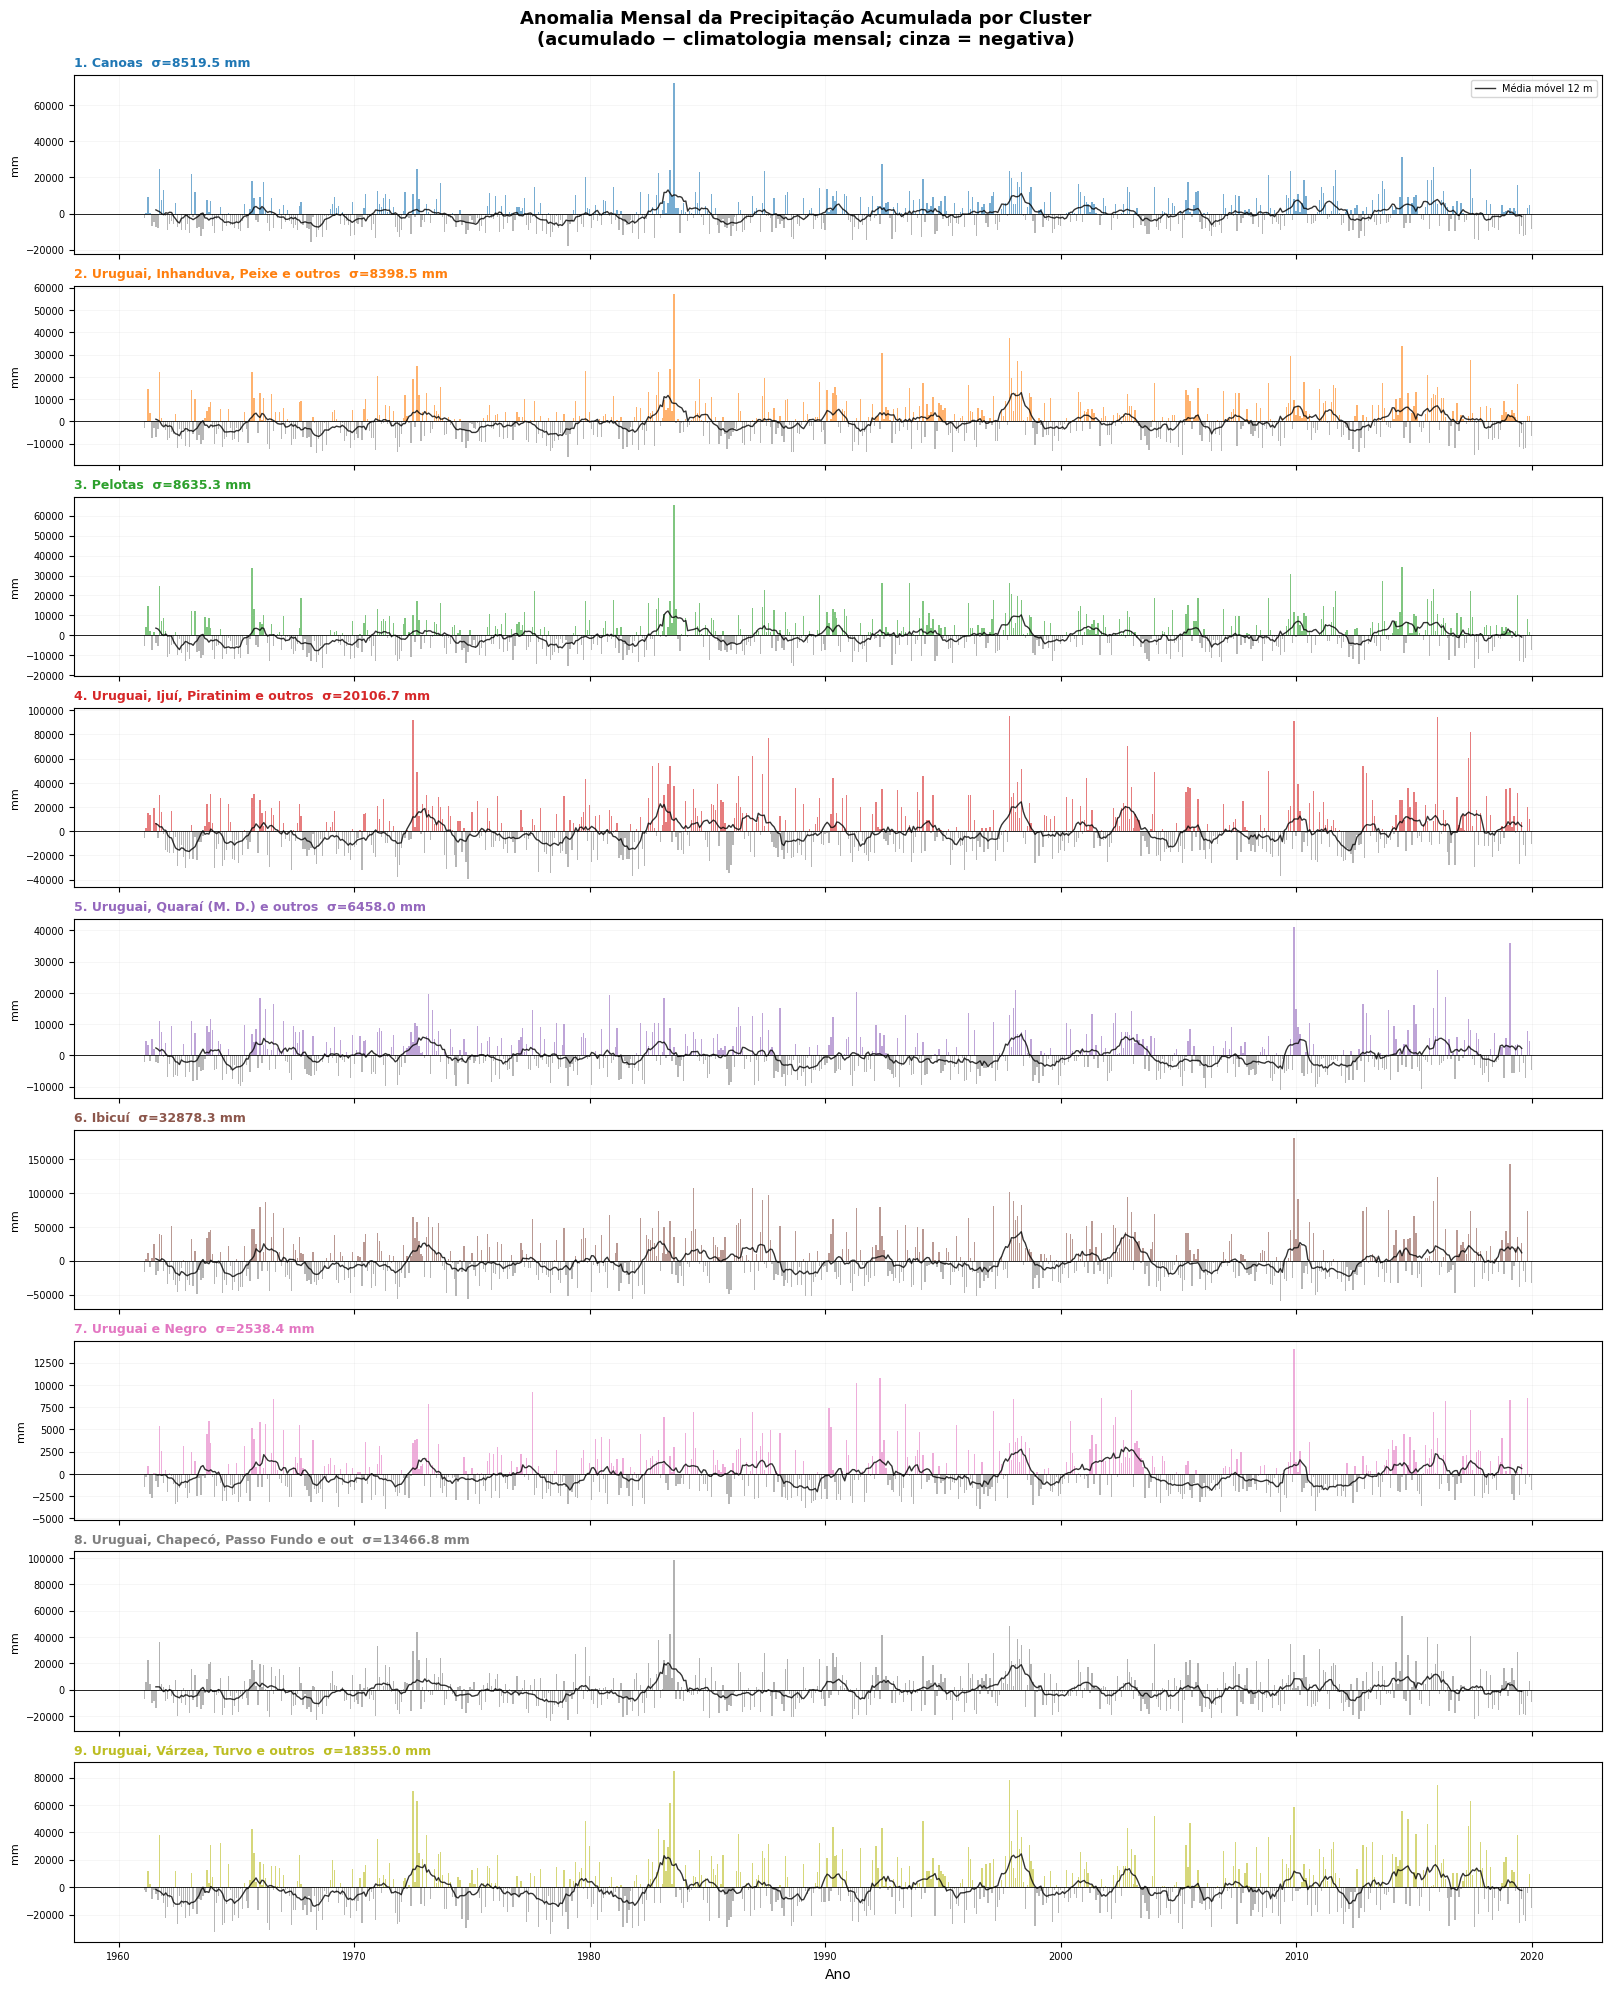

Figura salva em results/uruguai_clusters_anomalia.png


In [ ]:
fig, axes = plt.subplots(n_clusters, 1,
                         figsize=(16, 2.2 * n_clusters),
                         sharex=True, constrained_layout=True)

for i, (name, d) in enumerate(cluster_data.items()):
    ax = axes[i]
    color = CLUSTER_CMAP(i)
    anom = d['anom']

    # Barras positivas/negativas
    bar_colors = [color if v >= 0 else '#888888' for v in anom]
    ax.bar(time_idx, anom, color=bar_colors, alpha=0.6, width=20, linewidth=0)
    ax.axhline(0, color='black', linewidth=0.6)

    # Média móvel 12 meses
    roll = pd.Series(anom).rolling(12, center=True).mean()
    ax.plot(time_idx, roll, color='black', linewidth=1.0, alpha=0.8,
            label='Média móvel 12 m')

    ax.set_ylabel('mm', fontsize=8)
    short = name[:35]
    ax.set_title(f'{i+1}. {short}  σ={anom.std():.1f} mm',
                 fontsize=9, color=color, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.2, linewidth=0.4)
    ax.tick_params(labelsize=7)
    if i == 0:
        ax.legend(fontsize=7, loc='upper right')

axes[-1].set_xlabel('Ano', fontsize=10)
fig.suptitle('Anomalia Mensal da Precipitação Acumulada por Cluster\n'
             '(acumulado − climatologia mensal; cinza = negativa)',
             fontsize=13, fontweight='bold')

fig.savefig(Path('../results') / 'uruguai_clusters_anomalia.png',
            dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em results/uruguai_clusters_anomalia.png')

---
## 7. Painel Resumo — Comparação entre Clusters

                                           N pontos  Acum. médio (mm/mês)  Anom. σ (mm)  Anom. mín (mm)  Anom. máx (mm)
Cluster                                                                                                                
1. Canoas                                       126               17262.2        8519.5        -17890.6         72249.8
2. Uruguai, Inhanduva, Peixe e outros           116               17408.6        8398.5        -15864.6         57246.5
3. Pelotas                                      130               18069.4        8635.3        -16211.5         65497.0
4. Uruguai, Ijuí, Piratinim e outros            250               36681.3       20106.7        -39584.5         95117.0
5. Uruguai, Quaraí (M. D.) e outros              95               10532.6        6458.0        -11102.2         41094.5
6. Ibicuí                                       450               59539.0       32878.3        -59402.2        181896.9
7. Uruguai e Negro                      

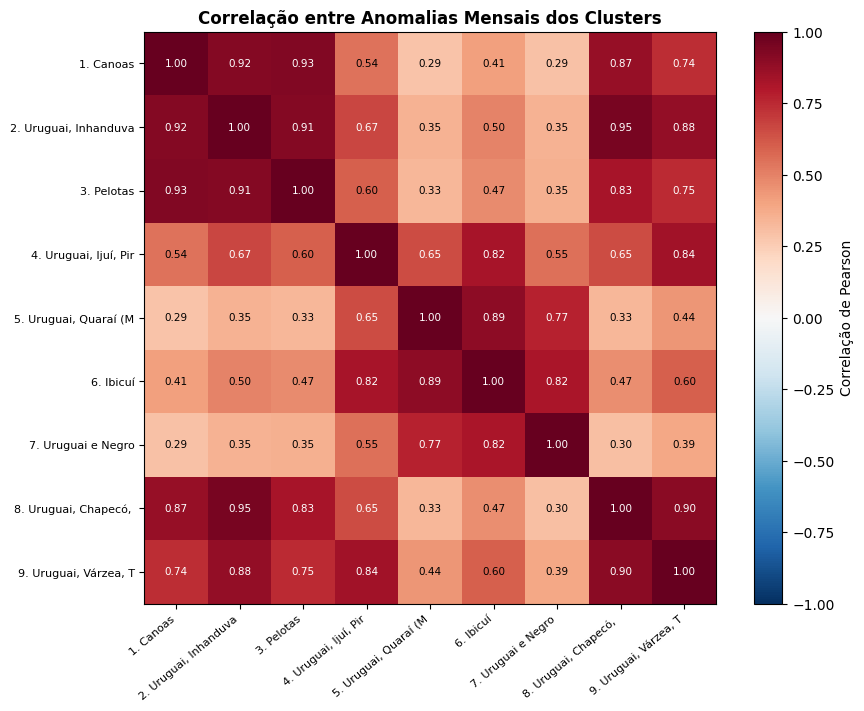

In [ ]:
# Tabela resumo
rows = []
for i, (name, d) in enumerate(cluster_data.items()):
    rows.append({
        'Cluster': f"{i+1}. {name[:40]}",
        'N pontos': d['n_pts'],
        'Acum. médio (mm/mês)': d['accum'].mean().round(1),
        'Anom. σ (mm)': d['anom'].std().round(1),
        'Anom. mín (mm)': d['anom'].min().round(1),
        'Anom. máx (mm)': d['anom'].max().round(1),
    })

df_summary = pd.DataFrame(rows).set_index('Cluster')
print(df_summary.to_string())

# Matriz de correlação entre anomalias dos clusters
anom_matrix = np.column_stack([d['anom'] for d in cluster_data.values()])
corr = np.corrcoef(anom_matrix.T)
short_labels = [f"{i+1}. {n[:18]}" for i, n in enumerate(cluster_names)]

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(n_clusters))
ax.set_xticklabels(short_labels, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(n_clusters))
ax.set_yticklabels(short_labels, fontsize=8)
for i in range(n_clusters):
    for j in range(n_clusters):
        ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center',
                fontsize=7.5,
                color='white' if abs(corr[i,j]) > 0.6 else 'black')
plt.colorbar(im, ax=ax, label='Correlação de Pearson', fraction=0.04)
ax.set_title('Correlação entre Anomalias Mensais dos Clusters',
             fontsize=12, fontweight='bold')

fig.savefig(Path('../results') / 'uruguai_clusters_correlacao.png',
            dpi=200, bbox_inches='tight')
plt.show()